<a href="https://colab.research.google.com/github/jun-yuaka/llm-book/blob/main/LLM_lesson%E2%91%A4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install transformers[ja,torch] "datasets<2.20.0" matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 26.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 MB 49.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 16.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 691.4/691.4 kB 15.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 MB 44.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 54.

In [2]:
from transformers.trainer_utils import set_seed

In [3]:
from pprint import pprint
from datasets import load_dataset

# MARC-jaの代わりに、推奨されている代替データセット WRIME を読み込みます
train_dataset = load_dataset(
    "llm-book/wrime-sentiment", split="train"
)

valid_dataset = load_dataset(
    "llm-book/wrime-sentiment", split="validation"
)

pprint(train_dataset[0])

Generating train split:   0%|          | 0/20149 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1608 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1781 [00:00<?, ? examples/s]

{'datetime': '2012/7/31 23:48',
 'label': 1,
 'sentence': 'ぼけっとしてたらこんな時間。チャリあるから食べにでたいのに…',
 'user_id': 1}


In [4]:
pprint(train_dataset.features)

{'datetime': Value(dtype='string', id=None),
 'label': ClassLabel(names=['positive', 'negative'], id=None),
 'sentence': Value(dtype='string', id=None),
 'user_id': Value(dtype='int64', id=None)}


In [5]:
from transformers import AutoTokenizer

# "cli-tohoku" ではなく "cl-tohoku" が正しいモデル名です
model_name = "cl-tohoku/bert-base-japanese-v3"
tokenizer = AutoTokenizer.from_pretrained(model_name)
print(type(tokenizer).__name__)

config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/251 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/231k [00:00<?, ?B/s]

BertJapaneseTokenizer


In [6]:
tokenizer.tokenize("これはテストです。")

['これ', 'は', 'テスト', 'です', '。']

In [7]:
encoded_input = tokenizer("これはテストです。")
print(type(encoded_input).__name__)

BatchEncoding


In [8]:
pprint(encoded_input)

{'attention_mask': [1, 1, 1, 1, 1, 1, 1],
 'input_ids': [2, 12538, 465, 14985, 13037, 385, 3]}


In [9]:
# 明示的に token_type_ids を返したい場合は引数に指定します
encoded_input_with_type = tokenizer("これはテストです。", return_token_type_ids=True)
pprint(encoded_input_with_type)

{'attention_mask': [1, 1, 1, 1, 1, 1, 1],
 'input_ids': [2, 12538, 465, 14985, 13037, 385, 3],
 'token_type_ids': [0, 0, 0, 0, 0, 0, 0]}


In [10]:
tokenizer.convert_ids_to_tokens(encoded_input["input_ids"])

['[CLS]', 'これ', 'は', 'テスト', 'です', '。', '[SEP]']

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|██████████| 20149/20149 [00:09<00:00, 2062.77it/s]


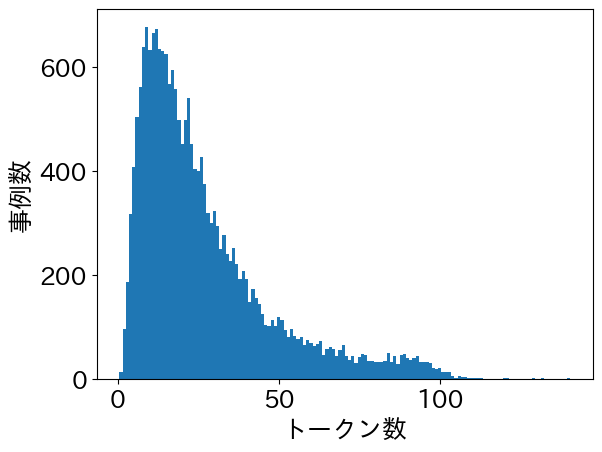

100%|██████████| 1608/1608 [00:01<00:00, 1465.33it/s]


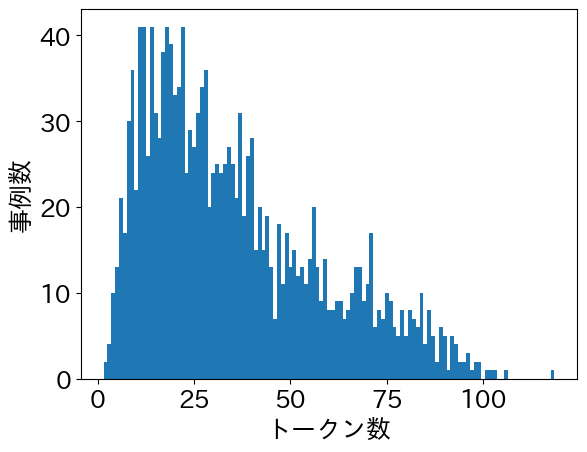

In [11]:
!pip install -q japanize-matplotlib

from collections import Counter
import japanize_matplotlib
import matplotlib.pyplot as plt
from datasets import Dataset
from tqdm import tqdm

plt.rcParams["font.size"] = 18

def visualize_text_length(dataset: Dataset):
  length_counter = Counter()
  for data in tqdm(dataset):
    length = len(tokenizer.tokenize(data["sentence"]))
    length_counter[length] += 1

  plt.bar(length_counter.keys(), length_counter.values(), width=1.0)
  plt.xlabel("トークン数")
  plt.ylabel("事例数")
  plt.show()

visualize_text_length(train_dataset)
visualize_text_length(valid_dataset)

In [12]:
for data in valid_dataset:
  if len(tokenizer.tokenize(data["sentence"])) < 10:
    pprint(data)

{'datetime': '2020/5/15 17:35',
 'label': 1,
 'sentence': 'よくわからない連携。',
 'user_id': 26}
{'datetime': '2020/5/15 17:47',
 'label': 1,
 'sentence': 'この3年が無駄になった。',
 'user_id': 26}
{'datetime': '2020/5/15 17:48',
 'label': 1,
 'sentence': '空気を読んでなくて。',
 'user_id': 26}
{'datetime': '2020/5/15 17:52',
 'label': 1,
 'sentence': 'っていうか、英語の聞きすぎ',
 'user_id': 26}
{'datetime': '2020/5/18 16:31',
 'label': 0,
 'sentence': '明日は楽しみかも。',
 'user_id': 26}
{'datetime': '2020/5/19 11:55',
 'label': 1,
 'sentence': '今日は誤字だらけ。',
 'user_id': 26}
{'datetime': '2020/5/21 8:29',
 'label': 0,
 'sentence': 'SUNがいいなと思った。',
 'user_id': 26}
{'datetime': '2020/5/5 6:50',
 'label': 0,
 'sentence': 'わさび醤油、結構合う。',
 'user_id': 28}
{'datetime': '2020/5/6 6:13',
 'label': 1,
 'sentence': '朝から本当に腹立たしい。',
 'user_id': 28}
{'datetime': '2020/5/6 6:27',
 'label': 1,
 'sentence': 'しかも本人は反省の色なし',
 'user_id': 28}
{'datetime': '2020/5/6 8:18', 'label': 1, 'sentence': '書けない', 'user_id': 28}
{'datetime': '2020/3/2 19:32',
 'label':

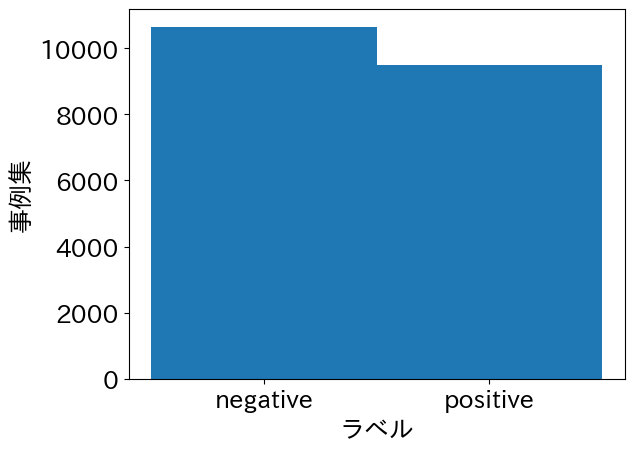

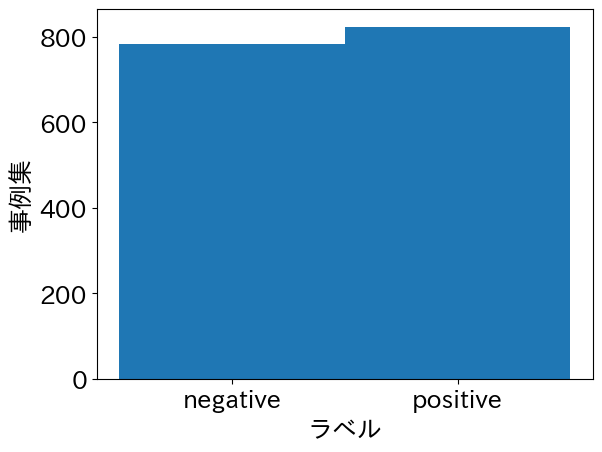

In [13]:
def visualize_labels(dataset: Dataset):
  label_counter = Counter()
  for data in dataset:
    label_id = data["label"]
    label_name = dataset.features["label"].names[label_id]
    label_counter[label_name] += 1
  plt.bar(label_counter.keys(), label_counter.values(), width=1.0)
  plt.xlabel("ラベル")
  plt.ylabel("事例集")
  plt.show()

visualize_labels(train_dataset)
visualize_labels(valid_dataset)

In [14]:
from transformers import BatchEncoding

def preprocess_text_classification(
    example: dict[str, str | int]
) -> BatchEncoding:

    encoded_example = tokenizer(example["sentence"], max_length=512)
    encoded_example["labels"] = example["label"]
    return encoded_example

In [15]:
encoded_train_dataset = train_dataset.map(
    preprocess_text_classification,
    remove_columns=train_dataset.column_names,
)
encoded_valid_dataset = valid_dataset.map(
    preprocess_text_classification,
    remove_columns=valid_dataset.column_names,
)

Parameter 'function'=<function preprocess_text_classification at 0x7e489a04c7c0> of the transform datasets.arrow_dataset.Dataset._map_single couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only showed once. Subsequent hashing failures won't be showed.


Map:   0%|          | 0/20149 [00:00<?, ? examples/s]

Map:   0%|          | 0/1608 [00:00<?, ? examples/s]

In [16]:
print(encoded_train_dataset[0])

{'input_ids': [2, 478, 7139, 15269, 441, 456, 13123, 21311, 12671, 385, 12651, 7065, 12485, 12488, 13781, 461, 457, 13030, 464, 461, 29, 29, 29, 3], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': 1}


In [17]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [18]:
batch_inputs = data_collator(encoded_train_dataset[0:4])
pprint({name: tensor.size() for name, tensor in batch_inputs.items()})

{'attention_mask': torch.Size([4, 36]),
 'input_ids': torch.Size([4, 36]),
 'labels': torch.Size([4])}


In [19]:
from transformers import AutoModelForSequenceClassification

class_label = train_dataset.features["label"]
label2id = {label: id for id, label in enumerate(class_label.names)}
id2label = {id: label for id, label in enumerate(class_label.names)}
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=class_label.num_classes,
    label2id=label2id,
    id2label=id2label,
)
print(type(model).__name__)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  447MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cl-tohoku/bert-base-japanese-v3
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those 

BertForSequenceClassification


In [20]:
print(model.forward(**data_collator(encoded_train_dataset[0:4])))

SequenceClassifierOutput(loss=tensor(0.9988, grad_fn=<NllLossBackward0>), logits=tensor([[ 0.4248, -0.1884],
        [ 0.5204, -0.1005],
        [ 0.6972, -0.4018],
        [ 0.4711, -0.2725]], grad_fn=<AddmmBackward0>), hidden_states=None, attentions=None)


In [26]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="output_marc_ja",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    lr_scheduler_type="linear",
    warmup_steps=100,
    num_train_epochs=3,
    logging_strategy="epoch",
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=True,
)

In [28]:
import numpy as np

def compute_accuracy(
    eval_pred: tuple[np.ndarray, np.ndarray]
) -> dict[str, float]:

  predictions, labels = eval_pred
  predictions - np.argmax(predictions, axis=1)
  return {"accuracy": (predictions == labels).mean()}

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_train_dataset,
    eval_dataset=encoded_valid_dataset,
    data_collator=data_collator,
    compute_metrics=compute_accuracy,
)
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
